In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from arch import arch_model
from scipy.optimize import minimize
import seaborn as sns

In [2]:
files ={
    "CZK": "/Users/eddiechiu/Documents/GitHub/Thesis/data/Czech_koruna.csv",
    "DKK": "/Users/eddiechiu/Documents/GitHub/Thesis/data/Danish_krone.csv",
    "HUF": "/Users/eddiechiu/Documents/GitHub/Thesis/data/Hungarian_forint.csv",
    "PLN": "/Users/eddiechiu/Documents/GitHub/Thesis/data/Polish_zloty.csv",
    "RON": "/Users/eddiechiu/Documents/GitHub/Thesis/data/Romanian_leu.csv",
    "SEK": "/Users/eddiechiu/Documents/GitHub/Thesis/data/Swedish_krona.csv",
}


In [3]:
def load_data(path, currency):
    df = pd.read_csv(path)
    val_col = [c for c in df.columns if c not in ("DATE", "TIME PERIOD")][0]
    out = df[["DATE", val_col]].copy()
    out.columns = ["date", currency]
    out["date"] = pd.to_datetime(out["date"])
    out[currency] = pd.to_numeric(out[currency], errors="coerce")
    return out.set_index("date").sort_index()

rates = pd.concat([load_data(p, c) for c, p in files.items()], axis=1)

In [4]:
rates = rates.loc["2005-01-01":"2025-12-31"] 
rates= rates.dropna()

returns= np.log(rates/ rates.shift(1)).dropna()


In [5]:
from garch import annual_volatility

vol_panel, fits = annual_volatility(returns, model="garch")
print(vol_panel.head())

# TGARCH for the robustness specification
vol_panel_t, fits_t = annual_volatility(returns, model="tgarch")
print(vol_panel_t.head())


GARCH   LL=    377.54  omega=0.00011  persistence=0.999994  nu=5.09  starts 26/26  distinct=1  [at bound: omega=floor, persistence=1]
GARCH   LL=  16340.30  omega=0.00000  persistence=0.999994  nu=3.86  starts 26/26  distinct=1  [at bound: persistence=1]
GARCH   LL=  -3340.64  omega=0.00155  persistence=0.996745  nu=7.78  starts 26/26  distinct=1
GARCH   LL=  -2452.41  omega=0.00136  persistence=0.998716  nu=6.53  starts 26/26  distinct=1
GARCH   LL=   2426.69  omega=0.00010  persistence=0.999994  nu=4.24  starts 26/26  distinct=1  [at bound: omega=floor, persistence=1]
GARCH   LL=  -2284.22  omega=0.00204  persistence=0.988569  nu=7.82  starts 26/26  distinct=1
  country  year  volatility
0     CZK  2005    0.003139
1     CZK  2006    0.002364
2     CZK  2007    0.002613
3     CZK  2008    0.005737
4     CZK  2009    0.005949
TGARCH  LL=    378.45  omega=0.00011  persistence=0.999994  nu=5.11  starts 26/26  distinct=1  [at bound: omega=floor, persistence=1]
TGARCH  LL=  16340.69  omeg

## Stage 2 -- Panel regression

`src/panel.py` takes the stage-1 volatility panel (`vol_panel`, keyed by currency)
and estimates

    growth = a_i + t_t + b1*vol + b2*trade_int + b3*(vol x trade) + controls + e

Real GDP growth is `CLV_PCH_PRE` (chain-linked volumes), not `CP_MEUR`: euro-denominated
GDP moves mechanically with the exchange rate, which would put the regressor inside the
dependent variable.

`run()` maps currency codes to country codes before merging, asserts the row count after
every merge, centers volatility and trade intensity before forming the interaction, then
reports collinearity, the three specifications, and the diagnostics.

In [6]:
import importlib
import panel as pnl

# Python caches imported modules in sys.modules, so re-running this cell after editing
# panel.py silently hands back the OLD module object -- the symptom is AttributeError on
# a function you can see in the file. Reloading picks the edits up without a kernel restart.
importlib.reload(pnl)

# Full specification: all three controls now span 2005-2024, so this is N=120.
panel, fits = pnl.run(vol_panel)

PANEL ASSEMBLY
  . volatility (after ccy -> geo)      rows= 120 (expected 120)
  . + real GDP growth                  rows= 120 (expected 120)
  . + trade intensity                  rows= 120 (expected 120)
  . + gfcf_pct_gdp                     rows= 120 (expected 120)
  . + hicp                             rows= 120 (expected 120)
  . + gov_exp_pct_gdp                  rows= 120 (expected 120)
  . final panel                        rows= 120 (expected 120)

COLLINEARITY
                 VIF(centered)  VIF(raw)
vol_c                     1.25      5.91
trade_c                   1.19      4.75
vol_x_trade               1.37     12.28
gfcf_pct_gdp              1.25      1.25
hicp                      1.34      1.34
gov_exp_pct_gdp           1.42      1.42
Flag: VIF > 10.

POOLED OLS   N=120  R2=0.1505  within-df=113
                        coef    se(DK)    p(DK)   p(OLS)   p(HAC)   p(clu)
vol_c                -1.3958    1.4433   0.3356   0.3114   0.3334   0.2464
trade_c               0.

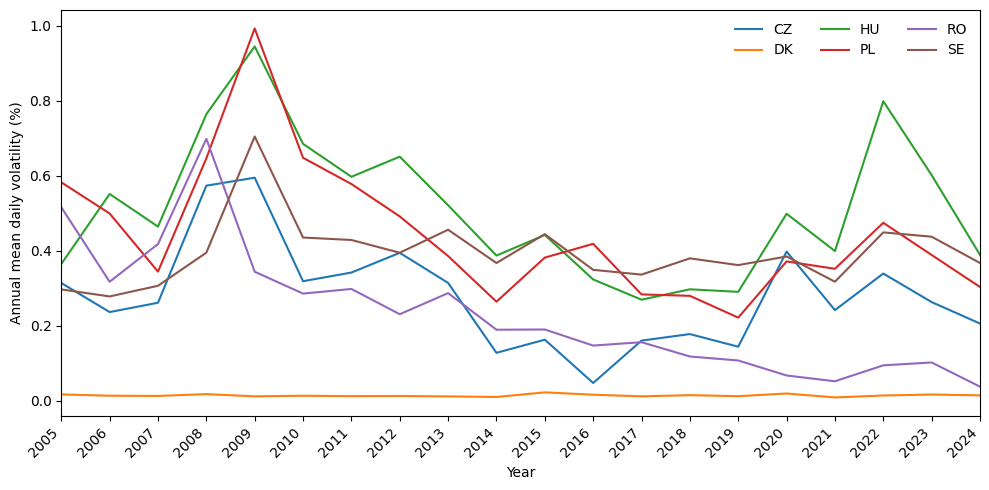

In [23]:
# --- Volatility over time, and the correlation matrix ------------------------
# Needs `panel` (built by pnl.run above), so it must sit BELOW that cell: `vol` only
# exists after the merge, and it is in percent (VOL_SCALE), not decimal.
vol_wide = panel.pivot(index="year", columns="country", values="vol")

fig, ax = plt.subplots(figsize=(10, 5))
for c in vol_wide.columns:
    ax.plot(vol_wide.index, vol_wide[c], label=c, linewidth=1.5)

ax.set_xlabel("Year")
ax.set_ylabel("Annual mean daily volatility (%)")
ax.set_xticks(vol_wide.index)                       # a tick for every year in the data
ax.set_xticklabels(vol_wide.index, rotation=45, ha="right")
ax.set_xlim(vol_wide.index.min(), vol_wide.index.max())   # kills the empty margins
ax.legend(ncol=3, frameon=False)
plt.tight_layout()
plt.savefig("volatility.pdf")                       # vector, for the thesis
plt.savefig("volatility.png", dpi=200)              # keep if you want a preview


In [24]:
# --- Descriptive statistics --------------------------------------------------
# Reported on the LEVEL variables, not the centered ones that enter the regression.
# vol_c and trade_c are demeaned in panel.py, so their means are 0 by construction and
# tabulating them would tell the reader nothing. The levels are the scale the
# coefficients are denominated in, which is what is needed to judge whether an estimate
# is economically large rather than merely significant.
#
# All six are in percentage points, but of different things, so read across a row and
# not down a column:
#   growth, hicp                              annual % change
#   trade_int, gfcf_pct_gdp, gov_exp_pct_gdp  % of GDP
#   vol                                       % of a DAILY log return (VOL_SCALE = 100)
# vol's mean is therefore a daily figure, not an annualised one -- it is not directly
# comparable to the other rows despite sharing the unit "percent".

LEVELS = ["growth", "vol", "trade_int", "gfcf_pct_gdp", "hicp", "gov_exp_pct_gdp"]
LABELS = {"growth":          "Real GDP growth",
          "vol":             "Exchange rate volatility",
          "trade_int":       "Euro-area trade intensity",
          "gfcf_pct_gdp":    "Investment (GFCF)",
          "hicp":            "Inflation (HICP)",
          "gov_exp_pct_gdp": "Government expenditure"}

desc = panel[LEVELS].agg(["count", "mean", "std", "min", "max"]).T
desc.columns = ["N", "mean", "sd", "min", "max"]
desc["N"] = desc["N"].astype(int)

print(f"Descriptive statistics: {panel['country'].nunique()} countries, "
      f"{int(panel['year'].min())}-{int(panel['year'].max())}, N = {len(panel)}\n")
print(desc.round(3).to_string())

# Every row must be 120. A short row means a control has gaps, and estimate() would
# quietly drop those observations -- this makes it visible here instead of showing up
# later as an unexplained change in the reported N.
assert (desc["N"] == len(panel)).all(), "missing values present; check load_controls()"

# LaTeX for results.tex, generated rather than typed. The (3,89) slip in tab:wald3 came
# from hand-transcribing numbers out of this notebook, so emit them ready to paste.
print("\n" + "-" * 78 + "\n")
print(r"\begin{table}[H]")
print(r"    \centering")
print(r"    \begin{tabular}{lccccc}")
print(r"        \toprule")
print(r"        \textbf{Variable} & \textbf{N} & \textbf{Mean} & \textbf{SD} "
      r"& \textbf{Min} & \textbf{Max} \\")
print(r"        \midrule")
for v in LEVELS:
    r = desc.loc[v]
    print(f"        {LABELS[v]} & {r['N']:.0f} & {r['mean']:.2f} & {r['sd']:.2f} "
          f"& {r['min']:.2f} & {r['max']:.2f} \\\\")
print(r"        \bottomrule")
print(r"    \end{tabular}")
print(r"    \caption{Descriptive statistics for the estimation sample: six European "
      r"Union member states outside the euro area, 2005--2024. All variables are in "
      r"percentage points; volatility is expressed per daily log return.}")
print(r"    \label{tab:descriptive}")
print(r"\end{table}")

Descriptive statistics: 6 countries, 2005-2024, N = 120

                   N    mean      sd     min      max
growth           120   2.397   3.066  -6.700    9.300
vol              120   0.313   0.216   0.009    0.993
trade_int        120  51.603  26.190  23.563  100.817
gfcf_pct_gdp     120  23.279   3.386  16.436   37.287
hicp             120   3.332   3.381  -1.100   17.000
gov_exp_pct_gdp  120  45.909   5.649  33.500   57.900

------------------------------------------------------------------------------

\begin{table}[H]
    \centering
    \begin{tabular}{lccccc}
        \toprule
        \textbf{Variable} & \textbf{N} & \textbf{Mean} & \textbf{SD} & \textbf{Min} & \textbf{Max} \\
        \midrule
        Real GDP growth & 120 & 2.40 & 3.07 & -6.70 & 9.30 \\
        Exchange rate volatility & 120 & 0.31 & 0.22 & 0.01 & 0.99 \\
        Euro-area trade intensity & 120 & 51.60 & 26.19 & 23.56 & 100.82 \\
        Investment (GFCF) & 120 & 23.28 & 3.39 & 16.44 & 37.29 \\
        Inflat

In [25]:
# --- Dropping GFCF, to isolate what that control contributes ------------------
# Same 120 observations either way, so any coefficient movement here is the control
# doing work rather than a change of sample.
panel_noi, fits_noi = pnl.run(vol_panel, controls=["hicp", "gov_exp_pct_gdp"])

PANEL ASSEMBLY
  . volatility (after ccy -> geo)      rows= 120 (expected 120)
  . + real GDP growth                  rows= 120 (expected 120)
  . + trade intensity                  rows= 120 (expected 120)
  . + gfcf_pct_gdp                     rows= 120 (expected 120)
  . + hicp                             rows= 120 (expected 120)
  . + gov_exp_pct_gdp                  rows= 120 (expected 120)
  . final panel                        rows= 120 (expected 120)

COLLINEARITY
                 VIF(centered)  VIF(raw)
vol_c                     1.24      5.84
trade_c                   1.17      4.61
vol_x_trade               1.35     12.10
hicp                      1.27      1.27
gov_exp_pct_gdp           1.35      1.35
Flag: VIF > 10.

POOLED OLS   N=120  R2=0.1505  within-df=114
                        coef    se(DK)    p(DK)   p(OLS)   p(HAC)   p(clu)
vol_c                -1.3922    1.4233   0.3301   0.3102   0.3283   0.2494
trade_c               0.0001    0.0062   0.9837   0.9907   0.9909

In [26]:
# --- Robustness: TGARCH volatility in place of GARCH -------------------------
# Same specification, stage-1 volatility from the leverage model. If the interaction
# depends on which volatility model generated the regressor, that is worth knowing.
panel_tg, fits_tg = pnl.run(vol_panel_t)

PANEL ASSEMBLY
  . volatility (after ccy -> geo)      rows= 120 (expected 120)
  . + real GDP growth                  rows= 120 (expected 120)
  . + trade intensity                  rows= 120 (expected 120)
  . + gfcf_pct_gdp                     rows= 120 (expected 120)
  . + hicp                             rows= 120 (expected 120)
  . + gov_exp_pct_gdp                  rows= 120 (expected 120)
  . final panel                        rows= 120 (expected 120)

COLLINEARITY
                 VIF(centered)  VIF(raw)
vol_c                     1.24      5.89
trade_c                   1.19      4.74
vol_x_trade               1.37     12.25
gfcf_pct_gdp              1.25      1.25
hicp                      1.34      1.34
gov_exp_pct_gdp           1.42      1.42
Flag: VIF > 10.

POOLED OLS   N=120  R2=0.1497  within-df=113
                        coef    se(DK)    p(DK)   p(OLS)   p(HAC)   p(clu)
vol_c                -1.3603    1.4422   0.3476   0.3254   0.3456   0.2531
trade_c               0.

In [27]:
# --- Headline coefficients side by side --------------------------------------
import pandas as pd

rows = {}
for lab, f in [("GARCH", fits), ("TGARCH", fits_tg), ("GARCH, no GFCF", fits_noi)]:
    ols, se_dk, p_dk = f["twoway"][:3]
    cols = list(ols.model.exog_names)
    for v in ["vol_c", "trade_c", "vol_x_trade"]:
        i = cols.index(v)
        rows.setdefault(v, {})[lab] = f"{ols.params[v]:+.4f} (p={p_dk[i]:.3f})"

print("Two-way FE, Driscoll-Kraay p-values")
print(pd.DataFrame(rows).T.to_string())

Two-way FE, Driscoll-Kraay p-values
                         GARCH             TGARCH     GARCH, no GFCF
vol_c        +3.6911 (p=0.117)  +3.6566 (p=0.115)  +5.6159 (p=0.038)
trade_c      +0.0510 (p=0.071)  +0.0522 (p=0.066)  +0.0227 (p=0.516)
vol_x_trade  -0.0961 (p=0.046)  -0.0925 (p=0.051)  -0.1384 (p=0.029)


### Diagnostic tests for the headline specification

The two-way fixed-effects model is re-estimated here explicitly so that every diagnostic
is computed from a residual vector visible in the notebook. `panel.py` runs the same
tests inside `run()` for the other specifications; the results below are identical.

Each test is reported with what rejection would mean for this model, not just a p-value.

In [28]:
# --- Rebuild the headline model explicitly -----------------------------------
import numpy as np, pandas as pd, statsmodels.api as sm

REG = ["vol_c", "trade_c", "vol_x_trade", "gfcf_pct_gdp", "hicp", "gov_exp_pct_gdp"]
est = panel.dropna(subset=["growth"] + REG).copy()

# Two-way FE as dummies, one category dropped in each dimension: the constant carries
# the omitted country-year cell, so the design does not fall into the dummy trap.
X = pd.concat([est[REG],
               pd.get_dummies(est["country"], prefix="c", drop_first=True, dtype=float),
               pd.get_dummies(est["year"],    prefix="y", drop_first=True, dtype=float)],
              axis=1)
X = sm.add_constant(X)

fit = sm.OLS(est["growth"], X).fit()
resid = fit.resid

print(f"N = {int(fit.nobs)}   parameters = {int(fit.df_model) + 1}   "
      f"residual df = {int(fit.df_resid)}   R2 = {fit.rsquared:.4f}")

N = 120   parameters = 31   residual df = 89   R2 = 0.7870


In [29]:
# --- 1. Multicollinearity: variance inflation factors ------------------------
# VIF_j = 1 / (1 - R2_j), where R2_j is from regressing regressor j on all the others.
# It answers: how much is Var(b_j) inflated by j being predictable from the rest?
#
# Computed twice on purpose. The raw product vol*trade is mechanically collinear with its
# own components, because
#       vol*trade = (vol-v_bar)(trade-t_bar) + t_bar*vol + v_bar*trade - v_bar*t_bar
# so it literally contains vol and trade as linear terms, weighted by the other's mean.
# Centering removes that. This is Marquardt's "nonessential ill-conditioning": it is an
# artifact of where zero sits, not a property of the data, and the interaction coefficient
# and its standard error are identical either way.
from statsmodels.stats.outliers_influence import variance_inflation_factor

vif_rows = {}
for lab, ixn in [("centered", est["vol_c"] * est["trade_c"]),
                 ("raw",      est["vol"]   * est["trade_int"])]:
    d = est[REG].copy()
    d["vol_x_trade"] = ixn
    M = sm.add_constant(d).values          # constant included, then skipped below
    vif_rows[lab] = pd.Series(
        [variance_inflation_factor(M, i + 1) for i in range(len(REG))], index=REG)

print(pd.DataFrame(vif_rows).round(2).to_string())
print("\nConventional flag is VIF > 10.")

                 centered    raw
vol_c                1.25   5.91
trade_c              1.19   4.75
vol_x_trade          1.37  12.28
gfcf_pct_gdp         1.25   1.25
hicp                 1.34   1.34
gov_exp_pct_gdp      1.42   1.42

Conventional flag is VIF > 10.


In [30]:
# --- 2. Between vs within variation: what can FE actually identify? ----------
# Country fixed effects absorb ALL cross-sectional variation, so each coefficient is
# identified only by movement over time within a country. A regressor whose variation is
# mostly between countries is therefore estimated off a thin slice of the data. No
# standard-error correction can repair this -- it is an identification limit, not an
# inference problem, which is why it is reported separately from the p-values.
rows = {}
for v in REG:
    g = est.groupby("country")[v]
    sd_b = g.mean().std(ddof=1)                       # sd of the 6 country means
    sd_w = (est[v] - g.transform("mean")).std(ddof=1)  # sd after demeaning
    rows[v] = {"sd_between": sd_b, "sd_within": sd_w, "ratio": sd_b / sd_w}

bw = pd.DataFrame(rows).T
print(bw.round(3).to_string())
print("\nRatio >> 1: mostly a cross-country characteristic, weakly identified under FE.")
print("Weakly identified here:", bw.index[bw["ratio"] > 3].tolist())

                 sd_between  sd_within  ratio
vol_c                 0.179      0.140  1.278
trade_c              27.941      5.466  5.112
vol_x_trade           4.309      3.582  1.203
gfcf_pct_gdp          2.692      2.319  1.161
hicp                  1.275      3.172  0.402
gov_exp_pct_gdp       5.617      2.324  2.417

Ratio >> 1: mostly a cross-country characteristic, weakly identified under FE.
Weakly identified here: ['trade_c']


In [31]:
# --- 3. Normality, heteroskedasticity, functional form -----------------------
from statsmodels.stats.stattools import jarque_bera
from statsmodels.stats.diagnostic import het_breuschpagan, linear_reset

# Jarque-Bera: H0 = residuals normal, built from skewness and excess kurtosis.
jb, jb_p, skew, kurt = jarque_bera(resid)
print(f"Jarque-Bera      stat={jb:7.2f}  p={jb_p:.4f}   "
      f"skew={skew:+.3f}  excess kurtosis={kurt - 3:+.3f}")
print("   H0: normal residuals. Rejection does NOT threaten consistency or unbiasedness")
print("   of the slopes -- only the exact small-sample t and F distributions, which the")
print("   Driscoll-Kraay standard errors replace anyway. Expected with macro data.\n")

# Breusch-Pagan: H0 = homoskedastic. Regresses squared residuals on the regressors.
bp, bp_p, bp_f, bp_fp = het_breuschpagan(resid, fit.model.exog)
print(f"Breusch-Pagan    stat={bp:7.2f}  p={bp_p:.4f}")
print("   H0: constant error variance. Rejection would mean OLS standard errors are")
print("   wrong; the robust estimators already handle it.\n")

# Ramsey RESET: adds powers of the fitted values. H0 = the linear form is adequate.
for power in (2, 3):
    r = linear_reset(fit, power=power, use_f=True)
    print(f"Ramsey RESET {power}   F={r.statistic:7.3f}  p={r.pvalue:.4f}")
print("   H0: no omitted non-linearity. This is the one test where NON-rejection is the")
print("   good outcome -- rejection would say the functional form itself is wrong.")

Jarque-Bera      stat=  53.78  p=0.0000   skew=-0.491  excess kurtosis=+3.129
   H0: normal residuals. Rejection does NOT threaten consistency or unbiasedness
   of the slopes -- only the exact small-sample t and F distributions, which the
   Driscoll-Kraay standard errors replace anyway. Expected with macro data.

Breusch-Pagan    stat=  39.15  p=0.1224
   H0: constant error variance. Rejection would mean OLS standard errors are
   wrong; the robust estimators already handle it.

Ramsey RESET 2   F=  0.004  p=0.9479
Ramsey RESET 3   F=  0.722  p=0.4887
   H0: no omitted non-linearity. This is the one test where NON-rejection is the
   good outcome -- rejection would say the functional form itself is wrong.


In [32]:
# --- 4. Serial correlation, lagged WITHIN each country -----------------------
# The lag must be taken inside each country. Lagging the stacked residual vector would
# splice Czechia's 2024 residual onto Denmark's 2005 residual and manufacture a spurious
# break at every panel boundary -- 5 fabricated pairs out of 114 here, all meaningless.
# groupby("country").shift(1) inserts NaN at each country's first year instead.
d = est[["country", "year"]].copy()
d["res"] = resid.values
d = d.sort_values(["country", "year"])
d["res_lag"] = d.groupby("country")["res"].shift(1)

print("First year of each country is NaN by construction, and dropped:")
print(d.groupby("country")["res_lag"].apply(lambda s: int(s.isna().sum())).to_string())

d = d.dropna(subset=["res_lag"])
ar = sm.OLS(d["res"], sm.add_constant(d["res_lag"])).fit()
rho, p_rho = ar.params["res_lag"], ar.pvalues["res_lag"]

print(f"\nWithin-country AR(1)   rho={rho:+.4f}  p={p_rho:.4f}  n={int(ar.nobs)}")
print("   H0: no first-order serial correlation in the residuals. Significant rho would")
print("   mean the Driscoll-Kraay lag truncation (maxlags=2) is too short.")
print("   Verdict:", "no evidence of serial correlation."
      if p_rho > 0.05 else "serial correlation present -- widen maxlags.")

First year of each country is NaN by construction, and dropped:
country
CZ    1
DK    1
HU    1
PL    1
RO    1
SE    1

Within-country AR(1)   rho=+0.1446  p=0.1177  n=114
   H0: no first-order serial correlation in the residuals. Significant rho would
   mean the Driscoll-Kraay lag truncation (maxlags=2) is too short.
   Verdict: no evidence of serial correlation.


In [33]:
# --- 5. Joint significance of trade_c and the interaction --------------------
# The individual t-statistics test one coefficient at a time, holding the other free.
# But "trade exposure plays no role" is a statement about BOTH trade_c and
# vol_x_trade at once, and the two are estimated jointly with a non-zero covariance.
# Testing them one at a time can therefore understate the evidence: each can look
# unremarkable while the pair rejects.
#
#     F = (Rb)' (R V R')^-1 (Rb) / q  ~  F(q, df_resid)
#
# V is the Driscoll-Kraay covariance, not the classical one, so the test inherits the
# same robustness as the headline standard errors. R selects the tested rows.
from scipy import stats as st

V_dk = pnl.driscoll_kraay_cov(est["growth"], X, est["year"].values, maxlags=2)
cols = list(X.columns)

print(f"Joint Wald tests, two-way FE, Driscoll-Kraay covariance  (N={int(fit.nobs)}, "
      f"df_resid={int(fit.df_resid)})\n")
print(f"{'':44s}{'F':>8s}{'df':>10s}{'p':>9s}")
for label, terms in [("trade_c = vol_x_trade = 0", ["trade_c", "vol_x_trade"]),
                     ("vol_c   = vol_x_trade = 0", ["vol_c", "vol_x_trade"]),
                     ("vol_c = trade_c = vol_x_trade = 0",
                      ["vol_c", "trade_c", "vol_x_trade"])]:
    F, q, dfr, p = pnl.wald_f(fit.params.values, V_dk, cols, terms, int(fit.df_resid))
    print(f"{label:44s}{F:8.3f}{f'({q},{dfr})':>10s}{p:9.4f}")

# Cross-check: with the classical covariance this must reproduce statsmodels' own
# f_test exactly. If it does, the machinery is right and only V differs above.
chk = fit.f_test("trade_c = 0, vol_x_trade = 0")
mine = pnl.wald_f(fit.params.values, fit.cov_params().values, cols,
                  ["trade_c", "vol_x_trade"], int(fit.df_resid))
print(f"\ncheck vs statsmodels f_test (classical V): "
      f"F={float(chk.fvalue):.6f} vs {mine[0]:.6f}, "
      f"p={float(chk.pvalue):.6f} vs {mine[3]:.6f}")


Joint Wald tests, two-way FE, Driscoll-Kraay covariance  (N=120, df_resid=89)

                                                   F        df        p
trade_c = vol_x_trade = 0                      4.721    (2,89)   0.0113
vol_c   = vol_x_trade = 0                      2.064    (2,89)   0.1330
vol_c = trade_c = vol_x_trade = 0              4.003    (3,89)   0.0101

check vs statsmodels f_test (classical V): F=3.099783 vs 3.099783, p=0.049957 vs 0.049957


In [34]:
# --- 6. Joint significance, model by model -----------------------------------
# Model 1  pooled OLS
# Model 2  country fixed effects
# Model 3  country + year fixed effects   (the specification the paper prefers)
#
# For each model:
#   overall F                 all slopes and dummies jointly zero -- model vs intercept
#   core three jointly = 0    do vol, trade and their interaction matter, as a block
#   country effects = 0       poolability: Model 1 vs Model 2
#   year effects = 0          poolability: Model 2 vs Model 3
#
# The last two are what justify the choice of specification. methodology.tex currently
# calls two-way FE "preferred" with no test behind it; these supply one.
#
# The core-three test is reported under BOTH covariances on purpose. Driscoll-Kraay is
# the paper's headline inference, but the classical column shows how much of the result
# is the estimator rather than the data.
#
# The dummy-block tests are classical ONLY, and that is a constraint rather than a
# choice. driscoll_kraay_cov sums moment conditions across countries within each year,
# so ht has one row per year -- 20 rows for 31 parameters in Model 3. S = ht'ht then has
# rank <= 20 in a 31-dimensional space and the 19-dimensional year-dummy block of V is
# singular, so a DK Wald test on the year effects is undefined. The rank is printed at
# the bottom so this is checkable rather than asserted. (The 2x2 and 3x3 blocks used
# elsewhere are generically fine, which is why the existing DK tests are unaffected.)
from scipy import stats as st

REG  = ["vol_c", "trade_c", "vol_x_trade", "gfcf_pct_gdp", "hicp", "gov_exp_pct_gdp"]
CORE = ["vol_c", "trade_c", "vol_x_trade"]
SPECS = [("Model 1 (pooled OLS)", "pooled"),
         ("Model 2 (country FE)", "country"),
         ("Model 3 (two-way FE)", "twoway")]

est = panel.dropna(subset=["growth"] + REG).copy()
y = est["growth"]

def f_block(fit, cols, terms):
    """Classical F that every coefficient in `terms` is jointly zero. The restriction
    matrix is built explicitly rather than passed as a formula string, so dummy names
    containing digits and underscores cannot be misparsed."""
    R = np.zeros((len(terms), len(cols)))
    for r, t in enumerate(terms):
        R[r, cols.index(t)] = 1.0
    res = fit.f_test(R)
    return float(res.fvalue), int(res.df_num), int(res.df_denom), float(res.pvalue)

def fmt(t):
    if t is None:
        return "--"
    F, dfn, dfd, p = t
    return f"{F:8.3f} ({dfn:>2d},{dfd:>3d})  {p:.4f}"

out, ranks = {}, {}
for label, spec in SPECS:
    # _design is what run() itself calls, so these are the same three models estimated
    # above rather than a re-implementation that could drift out of step.
    X = pnl._design(est, spec, REG)
    cols = list(X.columns)
    fit_s = sm.OLS(y, X).fit()

    cdums = [c for c in cols if c.startswith("c_")]
    ydums = [c for c in cols if c.startswith("y_")]

    # Within R2: the incremental fit of the regressors BEYOND the fixed effects alone.
    # Plain R2 is misleading across these three rows -- Model 3's 0.79 is mostly the
    # year dummies absorbing 2009 and 2020, not the regressors explaining more. For
    # Model 1 the "fixed effects only" model is just the intercept, so the two coincide.
    fe_only = sm.add_constant(X[cdums + ydums]) if (cdums or ydums) \
              else np.ones((len(est), 1))
    within = 1.0 - fit_s.ssr / sm.OLS(y, fe_only).fit().ssr

    V_dk = pnl.driscoll_kraay_cov(y, X, est["year"].values, maxlags=2)
    ht = pd.DataFrame(np.asarray(X, float) * np.asarray(fit_s.resid)[:, None]).groupby(
            est["year"].values).sum().values
    ranks[label] = (ht.shape, int(np.linalg.matrix_rank(ht.T @ ht)))

    out[label] = {
        "N":                             f"{int(fit_s.nobs)}",
        "parameters":                    f"{int(fit_s.df_model) + 1}",
        "residual df":                   f"{int(fit_s.df_resid)}",
        "R2":                            f"{fit_s.rsquared:.4f}",
        "within R2":                     f"{within:.4f}",
        "overall F (all terms = 0)":     fmt((fit_s.fvalue, int(fit_s.df_model),
                                              int(fit_s.df_resid), fit_s.f_pvalue)),
        "core three = 0  [classical]":   fmt(f_block(fit_s, cols, CORE)),
        "core three = 0  [Driscoll-Kraay]":
            fmt(pnl.wald_f(fit_s.params.values, V_dk, cols, CORE, int(fit_s.df_resid))),
        "country effects = 0  [1 vs 2]": fmt(f_block(fit_s, cols, cdums)) if cdums else "--",
        "year effects = 0     [2 vs 3]": fmt(f_block(fit_s, cols, ydums)) if ydums else "--",
    }

print(f"Joint significance by specification   (N = {len(est)}, "
      f"F statistic, (df num, df den), p)\n")
print(pd.DataFrame(out).to_string())

print("\nCaveat: the classical F-tests assume homoskedastic, serially uncorrelated errors")
print("-- the assumptions the Driscoll-Kraay errors exist to avoid. Read them as")
print("specification-selection evidence, not as inference to quote beside the coefficients.")

print("\nWhy the dummy blocks cannot use Driscoll-Kraay:")
for label, (shape, rk) in ranks.items():
    print(f"  {label:24s} ht is {shape[0]:>2d} x {shape[1]:<3d} -> rank(S) = {rk}"
          f"{'   (< parameters: dummy block singular)' if rk < shape[1] else ''}")

Joint significance by specification   (N = 120, F statistic, (df num, df den), p)

                                       Model 1 (pooled OLS)       Model 2 (country FE)       Model 3 (two-way FE)
N                                                       120                        120                        120
parameters                                                7                         12                         31
residual df                                             113                        108                         89
R2                                                   0.1505                     0.3472                     0.7870
within R2                                            0.1505                     0.2988                     0.2306
overall F (all terms = 0)            3.337 ( 6,113)  0.0046     5.222 (11,108)  0.0000    10.962 (30, 89)  0.0000
core three = 0  [classical]          0.755 ( 3,113)  0.5219     3.701 ( 3,108)  0.0140     2.484 ( 3, 89)  0.0659
core 

Cook's distance, two-way FE:  n = 120, p = 31, mean leverage = 0.258
thresholds:  4/n = 0.0333   4/(n-p) = 0.0449   |DFBETAS| > 2/sqrt(n) = 0.1826

Ten largest Cook's distances
 country  year     cooks  leverage  dfbetas(ixn)
      RO  2010    0.2059     0.234        -0.106
      SE  2010    0.0923     0.224         0.000
      PL  2009    0.0921     0.335        -0.717
      RO  2008    0.0883     0.459        -0.527
      DK  2022    0.0483     0.355         0.199
      RO  2017    0.0479     0.254         0.080
      HU  2022    0.0449     0.565         0.703
      PL  2005    0.0345     0.245         0.184
      SE  2022    0.0299     0.268         0.284
      CZ  2005    0.0274     0.255         0.209

Above 4/n = 0.0333:  8 of 120 observations (6.7%)
  RO2010, SE2010, PL2009, RO2008, DK2022, RO2017, HU2022, PL2005
Above the stricter 4/(n-p) = 0.0449:  6 observations

Of the 8 flagged observations, 2 (25.0%) fall in [2008, 2009, 2020]
Crisis years are 18/120 = 15.0% of the sample,

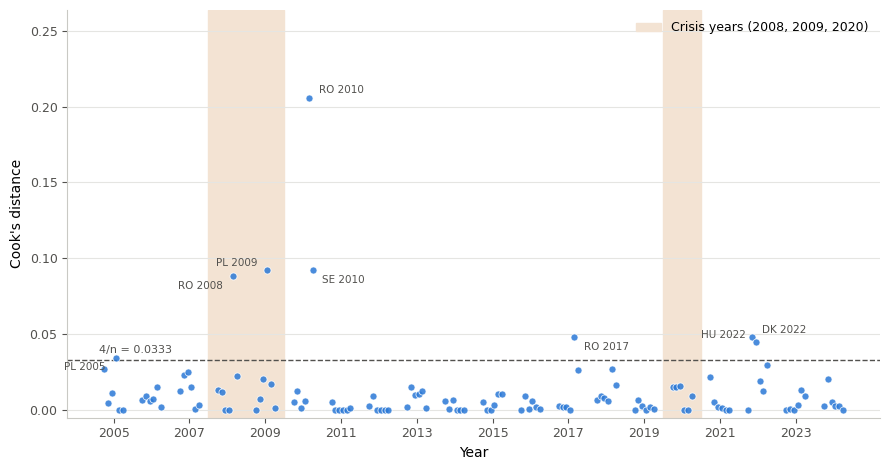

saved -> ../paper/fig/cooks_distance.png


In [35]:
# --- 7. Cook's distance: which observations move the coefficients? -----------
# D_i measures how far the WHOLE coefficient vector shifts when observation i is deleted:
#
#     D_i = (e_i^2 / (p * s^2)) * h_ii / (1 - h_ii)^2
#
# Two caveats that matter for how the numbers below should be read.
#
# 1. Cook's D is defined off the classical OLS variance, not Driscoll-Kraay. It is a
#    statement about the FIT -- which points pull the estimates -- not about the robust
#    inference. That is the right tool for "do particular observations drive the result",
#    but it does not translate into a corrected p-value.
#
# 2. The design has p = 31 parameters on n = 120 observations, so mean leverage is
#    p/n = 0.26 -- high by construction, because 19 year dummies are each identified off
#    6 observations. The conventional 4/n threshold will therefore flag more points here
#    than in a model with few regressors. 4/(n-p) is printed alongside as a stricter
#    alternative, and leverage is reported so a flag driven by h_ii rather than by the
#    residual is visible.
#
# DFBETAS for vol_x_trade is included too. Cook's D is an omnibus measure over all 31
# coefficients, most of them dummies nobody cares about; DFBETAS says how many standard
# errors THE INTERACTION moves when the observation is dropped, which is the actual
# question here. Conventional cut-off is 2/sqrt(n).
import os
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from statsmodels.stats.outliers_influence import OLSInfluence

CRISIS = [2008, 2009, 2020]
BLUE, MUTED, GRID, BAND = "#2a78d6", "#52514e", "#e5e5e2", "#f3e3d3"

infl  = OLSInfluence(fit)
n_obs = int(fit.nobs)
p_par = int(fit.df_model) + 1
thr, thr_strict = 4.0 / n_obs, 4.0 / (n_obs - p_par)
dfb_cut = 2.0 / np.sqrt(n_obs)
j_ixn = list(X.columns).index("vol_x_trade")

infl_df = pd.DataFrame({
    "country":  est["country"].values,
    "year":     est["year"].values,
    "cooks":    infl.cooks_distance[0],
    "leverage": infl.hat_matrix_diag,
    "dfb_ixn":  infl.dfbetas[:, j_ixn],
})
infl_df["crisis"] = infl_df["year"].isin(CRISIS)

print(f"Cook's distance, two-way FE:  n = {n_obs}, p = {p_par}, "
      f"mean leverage = {infl_df['leverage'].mean():.3f}")
print(f"thresholds:  4/n = {thr:.4f}   4/(n-p) = {thr_strict:.4f}   "
      f"|DFBETAS| > 2/sqrt(n) = {dfb_cut:.4f}\n")

print("Ten largest Cook's distances")
top10 = infl_df.sort_values("cooks", ascending=False).head(10)
print(f"{'country':>8s}{'year':>6s}{'cooks':>10s}{'leverage':>10s}{'dfbetas(ixn)':>14s}")
for _, r in top10.iterrows():
    print(f"{r['country']:>8s}{int(r['year']):>6d}{r['cooks']:>10.4f}"
          f"{r['leverage']:>10.3f}{r['dfb_ixn']:>14.3f}")

flag = infl_df[infl_df["cooks"] > thr].sort_values("cooks", ascending=False)
print(f"\nAbove 4/n = {thr:.4f}:  {len(flag)} of {n_obs} observations "
      f"({100*len(flag)/n_obs:.1f}%)")
print("  " + (", ".join(f"{r['country']}{int(r['year'])}" for _, r in flag.iterrows())
              if len(flag) else "none"))
n_strict = int((infl_df["cooks"] > thr_strict).sum())
print(f"Above the stricter 4/(n-p) = {thr_strict:.4f}:  {n_strict} observations")

# Is influence CONCENTRATED in the crisis years, or merely present in them? The share of
# flagged points that are crisis years only means something against the share of the
# SAMPLE that is crisis years -- 18/120 = 15% -- which is the baseline printed below.
n_crisis_obs = int(infl_df["crisis"].sum())
base_share   = 100 * n_crisis_obs / n_obs
if len(flag):
    got_share = 100 * int(flag["crisis"].sum()) / len(flag)
    verdict = "CONCENTRATED in" if got_share > base_share else "NOT concentrated in"
    print(f"\nOf the {len(flag)} flagged observations, {int(flag['crisis'].sum())} "
          f"({got_share:.1f}%) fall in {CRISIS}")
    print(f"Crisis years are {n_crisis_obs}/{n_obs} = {base_share:.1f}% of the sample, "
          f"so influence is {verdict} those years (ratio {got_share/base_share:.2f}x).")

mc  = infl_df.loc[infl_df["crisis"],  "cooks"]
mnc = infl_df.loc[~infl_df["crisis"], "cooks"]
print(f"\nmean Cook's D, crisis years ({len(mc)} obs)      = {mc.mean():.5f}   "
      f"median {mc.median():.5f}   max {mc.max():.5f}")
print(f"mean Cook's D, non-crisis years ({len(mnc)} obs)  = {mnc.mean():.5f}   "
      f"median {mnc.median():.5f}   max {mnc.max():.5f}")
print(f"ratio of means = {mc.mean()/mnc.mean():.2f}x")

big_dfb = infl_df[infl_df["dfb_ixn"].abs() > dfb_cut]
print(f"\n|DFBETAS| on vol_x_trade above {dfb_cut:.3f}: {len(big_dfb)} observations"
      + (f", of which {int(big_dfb['crisis'].sum())} are crisis years"
         if len(big_dfb) else ""))

# --- figure ------------------------------------------------------------------
MAXLAB = 15                       # labelling every flagged point becomes unreadable
fig, ax = plt.subplots(figsize=(9, 4.8))
for y in CRISIS:                  # +/-0.5 so 2008 and 2009 read as one episode
    ax.axvspan(y - .5, y + .5, color=BAND, zorder=0)
ax.axhline(thr, color=MUTED, ls="--", lw=1, zorder=2)

jit = (infl_df.groupby("country").ngroup() - 2.5) * 0.10   # separate the 6 countries
ax.scatter(infl_df["year"] + jit, infl_df["cooks"], s=26, color=BLUE, alpha=.85,
           zorder=3, edgecolor="white", lw=.6)
ax.set_ylim(-0.005, max(infl_df["cooks"].max() * 1.28, thr * 1.5))
ax.annotate(f"4/n = {thr:.4f}", (infl_df["year"].min() - 0.4, thr),
            xytext=(0, 5), textcoords="offset points", fontsize=8, color=MUTED)

for k, (i, r) in enumerate(flag.head(MAXLAB).iterrows()):
    dx, dy = [(7, 3), (7, -9), (-7, 3), (-7, -9)][k % 4]
    ax.annotate(f"{r['country']} {int(r['year'])}", (r["year"] + jit[i], r["cooks"]),
                textcoords="offset points", xytext=(dx, dy), fontsize=7.5,
                color=MUTED, zorder=4, ha="left" if dx > 0 else "right")

ax.set_xlabel("Year", fontsize=10)
ax.set_ylabel("Cook's distance", fontsize=10)
ax.set_xticks(range(2005, 2025, 2))
ax.grid(axis="y", color=GRID, lw=.8); ax.set_axisbelow(True)
for s in ("top", "right"): ax.spines[s].set_visible(False)
for s in ("left", "bottom"): ax.spines[s].set_color("#c9c9c4")
ax.tick_params(colors=MUTED, labelsize=9)
ax.legend(handles=[mpatches.Patch(color=BAND, label=f"Crisis years {tuple(CRISIS)}")],
          frameon=False, fontsize=9, loc="upper right")
plt.tight_layout()

OUT = os.path.join("..", "paper", "fig", "cooks_distance.png")
plt.savefig(OUT, dpi=200, bbox_inches="tight")
plt.show()
if len(flag) > MAXLAB:
    print(f"\nNote: {len(flag)} points exceed 4/n; only the {MAXLAB} largest are labelled.")
print(f"saved -> {OUT}")


### Diagnostics, marginal effects and robustness

The two cells below add what an interaction model needs on top of a coefficient table: the marginal effect of volatility across the range of trade intensity,
and the same specification re-estimated on subsamples.

In [36]:
# --- Marginal effect of volatility across trade intensity --------------------
# b1 is the effect at MEAN trade intensity, not "the effect of volatility". The effect at
# level t is b1 + b3*(t - mean), with Var = V11 + c^2*V33 + 2c*V13 -- the covariance term
# matters and is taken from the Driscoll-Kraay matrix.
me = pnl.marginal_effects(panel)


MARGINAL EFFECT OF VOLATILITY (twoway)
          trade_int  dGrowth/dVol      se       p
quantile                                         
q05         24.9610        6.2509  3.3543  0.0657
q25         28.2849        5.9315  3.2172  0.0686
q50         40.4673        4.7610  2.7339  0.0851
q75         78.5418        1.1026  1.6754  0.5122
q95         95.6407       -0.5403  1.6857  0.7493

Effect crosses zero at trade intensity 90.0% (sample range 23.6-100.8%)
Country mean trade intensity:
  DK=25.9  SE=27.6  RO=36.8  PL=46.6  HU=84.8  CZ=87.9


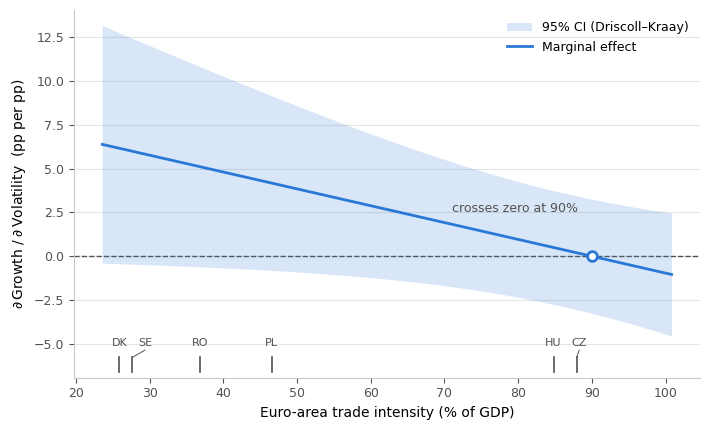

b1 = +3.6911   b3 = -0.0961   mean(trade) = 51.60
effect crosses zero at trade intensity 90.0%  (observed range 23.6-100.8%)
saved -> ../paper/fig/marginal_effect.png


In [37]:
# --- Marginal effect of volatility: plot -------------------------------------
# The table above evaluates the effect at five quantiles. The plot shows it across the
# WHOLE observed range of trade intensity, which is the point of an interaction model:
# a single coefficient hides that the effect changes sign inside the sample.
#
#   dGrowth/dVol at trade t  =  b1 + b3 * (t - mean(trade))
#   Var                      =  V11 + c^2*V33 + 2c*V13,   c = t - mean(trade)
#
# The covariance term is what makes the band narrow in the middle and flare at the ends:
# the effect is best determined near the mean, where most of the data sits. Dropping
# 2c*V13 would give a band of nearly constant width, which would be wrong.
import os
import matplotlib.pyplot as plt
import matplotlib.transforms as mtrans
from scipy import stats as st

REG  = ["vol_c", "trade_c", "vol_x_trade", "gfcf_pct_gdp", "hicp", "gov_exp_pct_gdp"]
BLUE, MUTED, GRID = "#2a78d6", "#52514e", "#e5e5e2"

est_p = panel.dropna(subset=["growth"] + REG).copy()
X_p   = pnl._design(est_p, "twoway", REG)          # same design run() estimates
fit_p = sm.OLS(est_p["growth"], X_p).fit()
V_p   = pnl.driscoll_kraay_cov(est_p["growth"], X_p, est_p["year"].values, maxlags=2)

cols_p = list(X_p.columns)
i1, i3 = cols_p.index("vol_c"), cols_p.index("vol_x_trade")
b1, b3 = fit_p.params["vol_c"], fit_p.params["vol_x_trade"]
tbar   = panel["trade_int"].mean()
dfr    = int(fit_p.df_resid)

t  = np.linspace(panel["trade_int"].min(), panel["trade_int"].max(), 300)
c  = t - tbar
me = b1 + b3 * c
se = np.sqrt(V_p[i1, i1] + c**2 * V_p[i3, i3] + 2 * c * V_p[i1, i3])
crit = st.t.ppf(0.975, dfr)
lo, hi = me - crit * se, me + crit * se
cross = tbar - b1 / b3

fig, ax = plt.subplots(figsize=(7.2, 4.4))
ax.axhline(0, color=MUTED, lw=1, ls="--", zorder=1)
ax.fill_between(t, lo, hi, color=BLUE, alpha=.18, lw=0, zorder=2,
                label="95% CI (Driscoll–Kraay)")


ax.plot(t, me,  color=BLUE, lw=2, zorder=3,
        label="Marginal effect")

# Mark the sign change only if it actually falls inside the observed range.
if t.min() < cross < t.max():
    ax.plot([cross], [0], "o", ms=7, mfc="white", mec=BLUE, mew=2, zorder=5)
    ax.annotate(f"crosses zero at {cross:.0f}%", (cross, 0), textcoords="offset points",
                xytext=(-10, 32), ha="right", fontsize=9, color=MUTED)

ax.set_ylim(ax.get_ylim()[0] - 1.5, ax.get_ylim()[1])      # headroom for the country rug

# Country mean trade intensity, so the reader can see WHERE each country sits on this
# curve -- the difference between "the effect turns negative" and "no country in the
# sample has reached the turning point".
tr = mtrans.blended_transform_factory(ax.transData, ax.transAxes)
pts = sorted(panel.groupby("country")["trade_int"].mean().items(), key=lambda p: p[1])
MINSEP, lab_x = 0.045 * (t.max() - t.min()), []           # spread labels that would collide
for _, x in pts:
    lab_x.append(x if not lab_x else max(x, lab_x[-1] + MINSEP))
for (cc, x), lx in zip(pts, lab_x):
    ax.plot([x, x], [0.015, 0.055], transform=tr, color=MUTED, lw=1.2, zorder=4, clip_on=False)
    if abs(lx - x) > 0.05:                                 # leader line if nudged
        ax.plot([x, lx], [0.055, 0.075], transform=tr, color=MUTED, lw=.7,
                zorder=4, clip_on=False)
    ax.annotate(cc, (lx, 0.085), xycoords=tr, ha="center", fontsize=8, color=MUTED)

ax.set_xlabel("Euro-area trade intensity (% of GDP)", fontsize=10)
ax.set_ylabel(r"$\partial\,$Growth $/\;\partial\,$Volatility  (pp per pp)", fontsize=10)
ax.grid(axis="y", color=GRID, lw=.8); ax.set_axisbelow(True)
for s in ("top", "right"): ax.spines[s].set_visible(False)
for s in ("left", "bottom"): ax.spines[s].set_color("#c9c9c4")
ax.tick_params(colors=MUTED, labelsize=9)
ax.legend(frameon=False, fontsize=9, loc="upper right")
plt.tight_layout()

# Saved straight into paper/fig so the figure the paper includes is the one this cell
# produced. (The volatility chart earlier writes to src/ and has to be copied by hand.)
OUT = os.path.join("..", "paper", "fig", "marginal_effect.png")
plt.savefig(OUT, dpi=300, bbox_inches="tight")
plt.show()

print(f"b1 = {b1:+.4f}   b3 = {b3:+.4f}   mean(trade) = {tbar:.2f}")
print(f"effect crosses zero at trade intensity {cross:.1f}%  "
      f"(observed range {t.min():.1f}-{t.max():.1f}%)")
print(f"saved -> {OUT}")

In [38]:
# --- Robustness: subsamples --------------------------------------------------
# Crisis years, the pegged currency, and leave-one-country-out. Centering is held at the
# full-sample origin so the rows stay comparable.
rob = pnl.robustness(panel)


ROBUSTNESS (twoway, Driscoll-Kraay p-values)
                                     N   vol_c  vol_c_p  trade_c  trade_c_p  vol_x_trade  vol_x_trade_p  F_trade  F_trade_p
full sample                      120.0  3.6911   0.1168   0.0510     0.0709      -0.0961         0.0462   4.7214     0.0113
excl. DKK (pegged)               100.0  3.6796   0.2702   0.0519     0.0149      -0.0961         0.0818  13.7952     0.0000
excl. crisis [2008, 2009, 2020]  102.0 -0.3114   0.8361   0.0528     0.1512       0.0016         0.9713   1.0778     0.3456
2010-2024 only                    90.0 -2.2944   0.2290   0.1045     0.0011       0.0101         0.8484   5.8781     0.0045
excl. COVID 2020-21              108.0  4.3601   0.0561   0.0662     0.0268      -0.0940         0.0443   5.3945     0.0064
drop CZ                          100.0  5.3779   0.0163   0.0931     0.0015      -0.1417         0.0040  10.1541     0.0001
drop DK                          100.0  3.6796   0.2702   0.0519     0.0149      -0.09